# 动态鲁棒定位与 SLAM · 代码展示

In [1]:
from pathlib import Path
import json, csv, hashlib, subprocess, os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image
from experiment_tools import local_url, videos, package, verify_files
ROOT = Path.cwd()
DATA = ROOT / 'evidence' if (ROOT / 'evidence').exists() else ROOT.parent.parent / 'results/reference'
REPO = Path(os.environ.get('SLAM_DEMO_REPO', r'D:\workspace\be2\slam_learning_updated'))
read = lambda p: json.loads(p.read_text(encoding='utf-8-sig'))
verify_files()

实验包,状态,核对文件,结果
robot-supp-static,executed,17,SHA-256 一致
robot-supp-dynamic,executed,17,SHA-256 一致
robot-supp-large-change,executed,32,SHA-256 一致
robot-corridor-v2-mapping,executed,17,SHA-256 一致
robot-live-static,executed,54,SHA-256 一致
robot-live-dynamic,executed,66,SHA-256 一致
robot-live-large-change,executed,54,SHA-256 一致
robot-corridor-v2,executed,68,SHA-256 一致
desktop-live-dufomap,executed,18,SHA-256 一致
desktop-live-beautymap,executed,20,SHA-256 一致


共核对 468 个记录绑定文件；大体积 ROS bag / 点云源文件仍保留在本机原始运行目录。


468

## 1. 原库执行

In [2]:
# dufomap：查看本次执行记录、命令和视频
record = read(DATA / 'desktop-live-dufomap' / 'record.json')
print(json.dumps({k:v for k,v in record.items() if k != 'artifacts'}, ensure_ascii=False, indent=2)[:7000])
videos('desktop-live-dufomap', result=False)

{
  "schema_version": 1,
  "kind": "author_desktop_demo",
  "status": "executed",
  "exit_code": 0,
  "method": "dufomap",
  "command": [
    "/home/qzl/projects/SLAM_Learning/.venv/bin/python",
    "-m",
    "slam_learning.cli",
    "_worker",
    "--root",
    "/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-202413-author-live-dufomap-2551ae/experiment",
    "--method",
    "dufomap",
    "--output",
    "/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-202413-author-live-dufomap-2551ae/experiment/results/runs/dufomap-9958d09fff88",
    "--frames",
    "0"
  ],
  "scope": "141 released KITTI-00 scans, pinned author pipeline; paper comparison as native record",
  "metrics": {
    "counts": {
      "kept_static": 16917434,
      "removed_static": 348813,
      "removed_dynamic": 94738,
      "kept_dynamic": 1245
    },
    "SA": 97.97979838930834,
    "DA": 98.70289530437681,
    "AA": 98.34068223458615,
    "HA": 98.3400176268

In [3]:
# 重新执行原库：需要时改为 True；Run All 默认只核对保存证据
RUN_LIVE = False
command = ['powershell.exe', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File',
           str(REPO / 'demo' / 'original-live.ps1'), '-Method', 'dufomap']
print(subprocess.list2cmdline(command))
if RUN_LIVE:
    subprocess.Popen(command)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original-live.ps1 -Method dufomap


In [4]:
# beautymap：查看本次执行记录、命令和视频
record = read(DATA / 'desktop-live-beautymap' / 'record.json')
print(json.dumps({k:v for k,v in record.items() if k != 'artifacts'}, ensure_ascii=False, indent=2)[:7000])
videos('desktop-live-beautymap', result=False)

{
  "schema_version": 1,
  "kind": "author_desktop_demo",
  "status": "executed",
  "exit_code": 0,
  "method": "beautymap",
  "command": [
    "/home/qzl/projects/SLAM_Learning/.venv/bin/python",
    "-m",
    "slam_learning.cli",
    "_worker",
    "--root",
    "/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-202609-author-live-beautymap-dbdf18/experiment",
    "--method",
    "beautymap",
    "--output",
    "/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-202609-author-live-beautymap-dbdf18/experiment/results/runs/beautymap-b9f4a4723ce8",
    "--frames",
    "0"
  ],
  "scope": "141 released KITTI-00 scans, pinned author pipeline; paper comparison as native record",
  "metrics": {
    "counts": {
      "kept_static": 16740135,
      "removed_static": 526112,
      "removed_dynamic": 94388,
      "kept_dynamic": 1595
    },
    "SA": 96.95294524629469,
    "DA": 98.33824739797673,
    "AA": 97.64313962379855,
    "HA": 97.

In [5]:
# 重新执行原库：需要时改为 True；Run All 默认只核对保存证据
RUN_LIVE = False
command = ['powershell.exe', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File',
           str(REPO / 'demo' / 'original-live.ps1'), '-Method', 'beautymap']
print(subprocess.list2cmdline(command))
if RUN_LIVE:
    subprocess.Popen(command)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original-live.ps1 -Method beautymap


In [6]:
# ir-mcl：查看本次执行记录、命令和视频
record = read(DATA / 'desktop-live-ir-mcl' / 'record.json')
print(json.dumps({k:v for k,v in record.items() if k != 'artifacts'}, ensure_ascii=False, indent=2)[:7000])
videos('desktop-live-ir-mcl', result=False)

{
  "schema_version": 1,
  "kind": "author_desktop_demo",
  "status": "executed",
  "exit_code": 0,
  "method": "ir-mcl",
  "command": [
    "/home/qzl/.venvs/ir-mcl/bin/python",
    "-u",
    "main.py",
    "--config_file",
    "./config/global_localization/loc_config_test1.yml"
  ],
  "scope": "released Bonn IPBLab sequence; native config and 100000 initial particles; fresh inference",
  "metrics": {
    "location_rmse_cm": 5.31,
    "yaw_rmse_deg": 1.07,
    "location_lt5_pct": 63.29,
    "location_lt10_pct": 96.09,
    "location_lt20_pct": 100.0,
    "yaw_lt0_5_pct": 47.34,
    "yaw_lt1_pct": 74.37,
    "yaw_lt2_pct": 93.5,
    "scored_poses": 1354
  },
  "source_run": "D:\\workspace\\be2\\slam_learning_updated\\results\\runs\\presentation\\20261014-201724-author-live-ir-mcl-ec568b",
  "live_state": {
    "enabled": true,
    "scope": "Actual RViz+terminal capture during new author execution; read-only current state, display thinning; observer overhead included"
  },
  "timing": {


In [7]:
# 重新执行原库：需要时改为 True；Run All 默认只核对保存证据
RUN_LIVE = False
command = ['powershell.exe', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File',
           str(REPO / 'demo' / 'original-live.ps1'), '-Method', 'ir-mcl']
print(subprocess.list2cmdline(command))
if RUN_LIVE:
    subprocess.Popen(command)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original-live.ps1 -Method ir-mcl


In [8]:
# adam-mcl：查看本次执行记录、命令和视频
record = read(DATA / 'desktop-adam-mcl' / 'record.json')
print(json.dumps({k:v for k,v in record.items() if k != 'artifacts'}, ensure_ascii=False, indent=2)[:7000])
videos('desktop-adam-mcl', result=True)

{
  "schema_version": 1,
  "kind": "author_desktop_demo",
  "method": "adam-mcl",
  "status": "executed",
  "exit_code": 0,
  "command": [
    "/home/qzl/.venvs/adam-mcl/bin/python",
    "-u",
    "repro/live_eval.py",
    "--python",
    "/home/qzl/.venvs/adam-mcl/bin/python",
    "--subdataset",
    "0",
    "--particles",
    "200",
    "--model",
    "/mnt/d/workspace/be2/tmp/repro/AdaM_MCL/Trained_models/simulation_2_2026-10-14 07:52:21.602839/model_train_38epochs.pth",
    "--trials",
    "1",
    "--log",
    "/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-173656-author-adam-mcl-f2821e/native-output.log"
  ],
  "scope": "author code; authored 128-cell surrogate; existing 2432-step checkpoint; fresh 123-update x 1-trial inference; no paper numeric comparison",
  "result_scope": "One fresh trial, saved upstream particle images and native errors, replayed using measured update durations; checkpoint/data surrogate disclosed",
  "metrics": {
    "positi

In [9]:
# 重新执行原库：需要时改为 True；Run All 默认只核对保存证据
RUN_LIVE = False
command = ['powershell.exe', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File',
           str(REPO / 'demo' / 'original.ps1'), '-Method', 'adam-mcl']
print(subprocess.list2cmdline(command))
if RUN_LIVE:
    subprocess.Popen(command)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original.ps1 -Method adam-mcl


## 2. 地图清理计数复算

In [10]:
for name in ('desktop-live-dufomap', 'desktop-live-beautymap'):
    metrics = read(DATA / name / 'metrics.json')
    counts = metrics['counts']
    sa = 100 * counts['kept_static'] / (counts['kept_static'] + counts['removed_static'])
    da = 100 * counts['removed_dynamic'] / (counts['kept_dynamic'] + counts['removed_dynamic'])
    print(name, 'SA', sa, 'DA', da, 'HA', 2*sa*da/(sa+da))
    print(counts, 'threshold_m=', metrics['threshold_m'])

desktop-live-dufomap SA 97.97979838930834 DA 98.70289530437681 HA 98.34001762682132
{'kept_static': 16917434, 'removed_static': 348813, 'removed_dynamic': 94738, 'kept_dynamic': 1245} threshold_m= 0.05
desktop-live-beautymap SA 96.95294524629469 DA 98.33824739797673 HA 97.6406829872703
{'kept_static': 16740135, 'removed_static': 526112, 'removed_dynamic': 94388, 'kept_dynamic': 1595} threshold_m= 0.05


## 3. IR-MCL 原生轨迹复算

N= 1354 RMSE cm= 5.313356278686989 yaw deg= 1.0741486271450587
{'location_rmse_cm': 5.31, 'yaw_rmse_deg': 1.07, 'location_lt5_pct': 63.29, 'location_lt10_pct': 96.09, 'location_lt20_pct': 100.0, 'yaw_lt0_5_pct': 47.34, 'yaw_lt1_pct': 74.37, 'yaw_lt2_pct': 93.5, 'scored_poses': 1354}


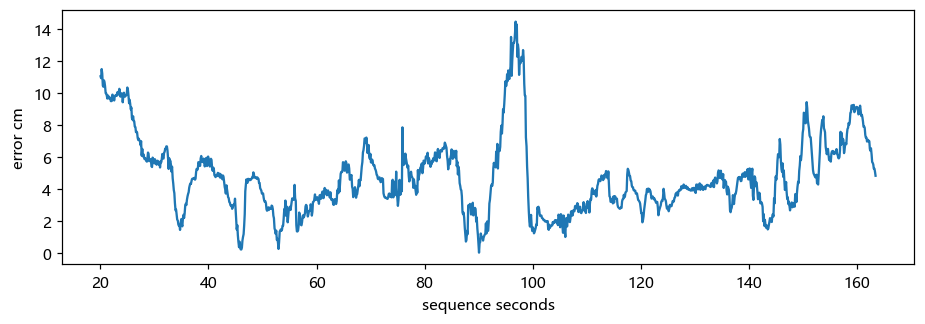

In [11]:
folder = DATA / 'desktop-live-ir-mcl'
gt = np.loadtxt(folder / 'seq_1_gt_pose.txt')
est = np.loadtxt(folder / 'IRMCL.txt')
assert gt.shape == est.shape and np.allclose(gt[:, 0], est[:, 0])
window = gt[:, 0] >= gt[0, 0] + 20
gt, est = gt[window], est[window]
error_cm = np.linalg.norm(est[:, 1:3] - gt[:, 1:3], axis=1) * 100
def yaw(tum):
    x,y,z,w = tum[:,4:8].T
    return np.arctan2(2*(w*z+x*y), 1-2*(y*y+z*z))
delta = yaw(est) - yaw(gt)
error_deg = np.rad2deg(np.arctan2(np.sin(delta), np.cos(delta)))
print('N=', len(gt), 'RMSE cm=', np.sqrt(np.mean(error_cm**2)), 'yaw deg=', np.sqrt(np.mean(error_deg**2)))
print(read(folder / 'metrics.json'))
plt.figure(figsize=(10,3)); plt.plot(gt[:,0], error_cm); plt.ylabel('error cm'); plt.xlabel('sequence seconds'); plt.show()

## 4. 机器人现场：建图 A → 固定地图 → 独立定位 B

In [12]:
# 双击入口只启动本机实时场景；评分读取下方封存数据
SCRIPTS = Path(r'F:\be2演讲\实机脚本')
for path in sorted(SCRIPTS.glob('*.bat')):
    print(path.name)
RUN_LIVE = False
SCRIPT = SCRIPTS / '20-静态_三方法独立RViz实时.bat'
if RUN_LIVE:
    subprocess.Popen(['cmd.exe', '/c', str(SCRIPT)])

00-查看本轮视频.bat


01-静态建图与三维点云.bat
02-动态建图与三维点云.bat
05-走廊点云建图.bat
08-处理最新走廊地图.bat
09-正常停止仿真.bat
10-处理最新静态地图.bat
11-处理最新动态地图.bat
20-静态_三方法独立RViz实时.bat
21-动态_三方法独立RViz实时.bat
22-持久变化_三方法独立RViz实时.bat
23-走廊退化_三方法独立RViz实时.bat
24-自动重录四场景_逐方法实时.bat
31-NDT三维定位_静态.bat
32-GICP三维定位_静态.bat
论文-adam-mcl.bat
论文-实时-beautymap.bat
论文-实时-dufomap.bat
论文-实时-ir-mcl.bat


In [13]:
# robot-supp-static：真实 Gazebo + RViz + 终端，及采集信息
videos('robot-supp-static', result=False)
print(read(DATA / 'robot-supp-static' / 'runtime.json'))
print(read(DATA / 'robot-supp-static' / 'metrics.json'))

{'world': '/mnt/d/workspace/be2/slam_learning_updated/config/presentation/worlds/S1_static.world', 'spawn': [8.0727, 7.5312, -1.5708], 'scene': 'static', 'world_sha256': '95091c22b2889b350b87487d58ad640094537f665da4b75593a27601803dadba', 'initial_offset': [0.25, 0.15, 0.12], 'scan_restore_after_s': None}


{'kind': 'live_native_ui_session', 'status': 'completed', 'failure': None, 'mode': 'mapping', 'points_received': 537, 'mapping_frames': 54, 'truth_source': 'Gazebo Pose_V named omni_car, top-level simulation timestamp', 'truth_used_for': 'evaluation/display; provided poses only in controlled mapping A', 'score_alignment': 'none; native author-derived maps and truth share world/map coordinates', 'score_sampling': 'native estimator pose updates; nearest truth within 0.05 simulation seconds', 'cases': {}, 'observed_map': {'width': 217, 'height': 143, 'resolution_m': 0.05000000074505806, 'known_cells': 20568}}


In [14]:
# robot-supp-dynamic：真实 Gazebo + RViz + 终端，及采集信息
videos('robot-supp-dynamic', result=False)
print(read(DATA / 'robot-supp-dynamic' / 'runtime.json'))
print(read(DATA / 'robot-supp-dynamic' / 'metrics.json'))

{'world': '/mnt/d/workspace/be2/slam_learning_updated/config/presentation/worlds/S2_dynamic.world', 'spawn': [8.0727, 7.5312, -1.5708], 'scene': 'dynamic', 'world_sha256': '6a5837880254d5647634247be12b6953438f87d5326682bcd2a376b2c6023e53', 'initial_offset': [0.25, 0.15, 0.12], 'scan_restore_after_s': None}
{'kind': 'live_native_ui_session', 'status': 'completed', 'failure': None, 'mode': 'mapping', 'points_received': 546, 'mapping_frames': 55, 'truth_source': 'Gazebo Pose_V named omni_car, top-level simulation timestamp', 'truth_used_for': 'evaluation/display; provided poses only in controlled mapping A', 'score_alignment': 'none; native author-derived maps and truth share world/map coordinates', 'score_sampling': 'native estimator pose updates; nearest truth within 0.05 simulation seconds', 'cases': {}, 'observed_map': {'width': 244, 'height': 143, 'resolution_m': 0.05000000074505806, 'known_cells': 20509}}


In [15]:
# robot-corridor-v2-mapping：真实 Gazebo + RViz + 终端，及采集信息
videos('robot-corridor-v2-mapping', result=False)
print(read(DATA / 'robot-corridor-v2-mapping' / 'runtime.json'))
print(read(DATA / 'robot-corridor-v2-mapping' / 'metrics.json'))

{'world': '/mnt/d/workspace/be2/slam_learning_updated/config/presentation/worlds/S4_degradation.world', 'spawn': [7.15, -3.1, 0.0], 'scene': 'corridor', 'world_sha256': 'e57fee1a83aa2b32b71d5ff4b19cdfed4cfae3d8330e12cc67ec4e807512bc6b', 'initial_offset': [1.0, 0.15, 0.12], 'scan_restore_after_s': 50.0}
{'kind': 'live_native_ui_session', 'status': 'completed', 'failure': None, 'mode': 'mapping', 'points_received': 744, 'mapping_frames': 75, 'truth_source': 'Gazebo Pose_V named omni_car, top-level simulation timestamp', 'truth_used_for': 'evaluation/display; provided poses only in controlled mapping A', 'score_alignment': 'none; native author-derived maps and truth share world/map coordinates', 'score_sampling': 'AMCL pose updates; nearest truth within 0.05 simulation seconds', 'cases': {}, 'observed_map': {'width': 482, 'height': 111, 'resolution_m': 0.05000000074505806, 'known_cells': 31115}}


## 5. 每种地图的现场执行与保存结果

In [16]:
def show_video(path, title):
    display(HTML(f'<b>{title}</b><video controls preload="none" width="900" src="{local_url(path)}"></video>'))
for name in ('robot-live-static','robot-live-dynamic','robot-live-large-change','robot-corridor-v2'):
    folder = DATA / name
    record = read(folder / 'record.json')
    print(name, record['source_run'])
    for view in record['native_views']:
        case = view['case']
        show_video(folder / view['video'], f'{name} / {case} / Live execution')
        show_video(folder / 'methods' / case / 'result.mp4', f'{name} / {case} / Measured result replay')

robot-live-static D:\workspace\be2\slam_learning_updated\results\runs\presentation\20261014-201016-localization-static-method-live-a72944


robot-live-dynamic D:\workspace\be2\slam_learning_updated\results\runs\presentation\20261014-201346-localization-dynamic-method-live-ed745f


robot-live-large-change D:\workspace\be2\slam_learning_updated\results\runs\presentation\20261014-201755-localization-large-change-method-live-05fc93


robot-corridor-v2 D:\workspace\be2\slam_learning_updated\results\runs\presentation\20261014-214224-localization-degradation-method-live-88a307


## 6. 实测误差：逐条时间关联与 RMSE

In [17]:
# e_i = hypot(estimate_x-truth_x, estimate_y-truth_y)
# RMSE = sqrt(mean(e_i**2)); yaw = atan2(sin(delta),cos(delta))
# 包含初始化；不拟合坐标；匹配上限 0.05 仿真秒。
for name in ('robot-live-static','robot-live-dynamic','robot-live-large-change','robot-corridor-v2'):
    folder = DATA / name
    truth = [json.loads(line) for line in (folder/'truth.jsonl').read_text().splitlines()]
    stamps = np.array([row['stamp_s'] for row in truth])
    for path in sorted(folder.glob('*-samples.csv')):
        rows = list(csv.DictReader(path.open(encoding='utf-8')))
        arr = {key:np.array([float(row[key]) for row in rows]) for key in rows[0]}
        xy = np.hypot(arr['estimate_x']-arr['truth_x'], arr['estimate_y']-arr['truth_y'])
        angle = arr['estimate_yaw']-arr['truth_yaw']
        angle = np.arctan2(np.sin(angle), np.cos(angle))
        assert np.allclose(xy,arr['position_error_m'])
        assert np.allclose(angle,arr['yaw_error_rad'])
        for i,stamp in enumerate(arr['stamp_s']):
            near = int(np.argmin(abs(stamps-stamp)))
            assert abs(stamps[near]-stamp) <= .05 + 1e-9
            assert np.allclose(truth[near]['xyz'][:2], [arr['truth_x'][i],arr['truth_y'][i]])
        print(name, path.stem, 'N=',len(rows), 'RMSE cm=', np.sqrt(np.mean(xy**2))*100,
              'yaw deg=', np.rad2deg(np.sqrt(np.mean(angle**2))))

robot-live-static beautymap-samples N= 290 RMSE cm= 6.890830689932812 yaw deg= 1.048481029710238


robot-live-static dufomap-samples N= 290 RMSE cm= 7.2797356048237285 yaw deg= 1.034383191048404


robot-live-static raw-samples N= 290 RMSE cm= 7.279735604823724 yaw deg= 1.0343831910484043
robot-live-dynamic beautymap-samples N= 288 RMSE cm= 7.138434320299081 yaw deg= 0.9804495804803086
robot-live-dynamic clean_beautymap-samples N= 288 RMSE cm= 6.777393259657562 yaw deg= 0.9726436770122688
robot-live-dynamic clean_dufomap-samples N= 288 RMSE cm= 7.081796512954093 yaw deg= 0.9949637461365421
robot-live-dynamic clean_raw-samples N= 288 RMSE cm= 7.081796512954093 yaw deg= 0.9949637461365426
robot-live-dynamic dufomap-samples N= 288 RMSE cm= 7.354178780479089 yaw deg= 1.0208502331187628


robot-live-dynamic raw-samples N= 288 RMSE cm= 7.413377821919909 yaw deg= 0.9680776697135087
robot-live-large-change beautymap-samples N= 290 RMSE cm= 6.3853469392372215 yaw deg= 1.0388999351001589


robot-live-large-change dufomap-samples N= 290 RMSE cm= 6.837866295344007 yaw deg= 1.0198390984575956


robot-live-large-change raw-samples N= 290 RMSE cm= 6.837866295344007 yaw deg= 1.0198390984575956
robot-corridor-v2 beautymap-samples N= 508 RMSE cm= 71.6034538089802 yaw deg= 0.8136684104818286


robot-corridor-v2 degraded_beautymap-samples N= 508 RMSE cm= 72.52638342027143 yaw deg= 0.8545970026150744
robot-corridor-v2 degraded_dufomap-samples N= 508 RMSE cm= 72.52638342027143 yaw deg= 0.8545970026150744
robot-corridor-v2 degraded_raw-samples N= 508 RMSE cm= 72.52638342027143 yaw deg= 0.8545970026150744
robot-corridor-v2 dufomap-samples N= 508 RMSE cm= 71.6034538089802 yaw deg= 0.8136684104818286
robot-corridor-v2 raw-samples N= 508 RMSE cm= 71.6034538089802 yaw deg= 0.8136684104818286


## 7. 新走廊：受限 → 恢复 → 持续确认

{
  "raw": {
    "restore_stamp_s": 66.2,
    "criterion": "position <0.1m and absolute yaw <5deg for 5 simulation seconds, >=8 native updates",
    "sustained_convergence_delay_s": 6.599999999999994,
    "converged": true,
    "scope": "recovery of an offset initial belief when full observations return; no physical kidnapping"
  },
  "dufomap": {
    "restore_stamp_s": 66.2,
    "criterion": "position <0.1m and absolute yaw <5deg for 5 simulation seconds, >=8 native updates",
    "sustained_convergence_delay_s": 6.599999999999994,
    "converged": true,
    "scope": "recovery of an offset initial belief when full observations return; no physical kidnapping"
  },
  "beautymap": {
    "restore_stamp_s": 66.2,
    "criterion": "position <0.1m and absolute yaw <5deg for 5 simulation seconds, >=8 native updates",
    "sustained_convergence_delay_s": 6.599999999999994,
    "converged": true,
    "scope": "recovery of an offset initial belief when full observations return; no physical kidnap

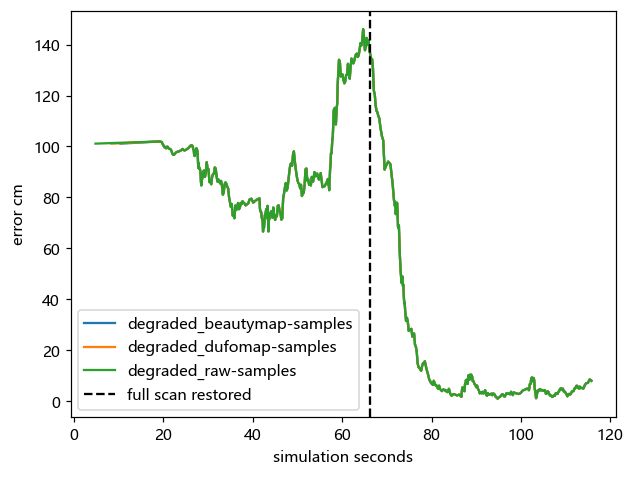

In [18]:
folder = DATA / 'robot-corridor-v2'
record = read(folder/'record.json')
print(json.dumps(record['restoration'], indent=2))
events = [json.loads(line) for line in (folder/'scan-stress.jsonl').read_text().splitlines()]
restore = min(row['stamp_s'] for row in events if row['phase']=='restored')
for path in sorted(folder.glob('degraded_*-samples.csv')):
    rows = list(csv.DictReader(path.open()))
    t=np.array([float(row['stamp_s']) for row in rows])
    e=np.array([float(row['position_error_m']) for row in rows])
    plt.plot(t,e*100,label=path.stem)
plt.axvline(restore,color='black',linestyle='--',label='full scan restored')
plt.xlabel('simulation seconds'); plt.ylabel('error cm'); plt.legend(); plt.show()

## 8. 三维固定地图定位：NDT / GICP

In [19]:
for name in ("robot-ndt-static", "robot-gicp-static"):
    videos(name)
    folder = DATA / name
    print(read(folder / "cases.json"))
    print(read(folder / "metrics.json")["cases"])
    for path in folder.glob("*-samples.csv"):
        rows = list(csv.DictReader(path.open()))
        error = np.array([np.hypot(float(r["estimate_x"])-float(r["truth_x"]),
                                    float(r["estimate_y"])-float(r["truth_y"])) for r in rows])
        print(name, len(error), np.sqrt(np.mean(error**2))*100, "cm")
# 同参数两轮都保留；差异原因待查，不挑选好看的结果。
print("NDT initial trial:", read(DATA / "robot-ndt-static-initial" / "metrics.json")["cases"])
print("NDT latest trial:", read(DATA / "robot-ndt-static" / "metrics.json")["cases"])

{'ndt': {'method': 'raw', 'map_yaml': '/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-163140-mapping-static-24597a/author-maps-20261014-165909/raw/map.yaml', 'mapping_scene': 'static', 'initial_pose': {'x': 8.3227, 'y': 7.6812000000000005, 'z': 0.0, 'yaw': -1.4508}, 'localizer': 'NDT_OMP', 'map_pcd': '/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-163140-mapping-static-24597a/author-maps-20261014-165909/raw-map.pcd', 'pose_topic': '/ndt/pcl_pose', 'native_map_odom_tf': True}}
{'ndt': {'samples': 402, 'dropped_unsynchronized': 1, 'position_rmse_m': 0.009270215223387042, 'yaw_rmse_deg': 0.17128034574914214, 'post_warmup_5s_samples': 361, 'post_warmup_5s_position_rmse_m': 0.009286064072528808, 'position_p95_m': 0.015813883735064014}}
robot-ndt-static 402 0.9270215223387042 cm


{'gicp': {'method': 'raw', 'map_yaml': '/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-163140-mapping-static-24597a/author-maps-20261014-165909/raw/map.yaml', 'mapping_scene': 'static', 'initial_pose': {'x': 8.3227, 'y': 7.6812000000000005, 'z': 0.0, 'yaw': -1.4508}, 'localizer': 'GICP', 'map_pcd': '/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-163140-mapping-static-24597a/author-maps-20261014-165909/raw-map.pcd', 'pose_topic': '/gicp/pcl_pose', 'native_map_odom_tf': True}}
{'gicp': {'samples': 397, 'dropped_unsynchronized': 1, 'position_rmse_m': 0.010910893890758328, 'yaw_rmse_deg': 0.1601187858899252, 'post_warmup_5s_samples': 368, 'post_warmup_5s_position_rmse_m': 0.011047977871584297, 'position_p95_m': 0.014853403815938799}}
robot-gicp-static 397 1.0910893890758329 cm
NDT initial trial: {'ndt': {'samples': 399, 'dropped_unsynchronized': 1, 'position_rmse_m': 0.34426276970654224, 'yaw_rmse_deg': 0.14846594120325204, 'pos